### My Question
What are the of chances of odd numbers landing on our dice after rolling? 


### My Study
Describe your simulation here:
1. As I am rolling the dice, I will observe wheter the number that has landed is either 1, 3 or 5. 
2. One trial gives an almost equal chance to all our 6 sides to land? so the chances of us having a 6 on our dice or a 3 on our dice is 1/6, or about 16%. As we roll more dices on a specific amount of numbers, those odds for any side will increase, but at lower numbers, the odds of landing a side will stay low. 
3. I am intrested in observing wheter 1 side of the dice will dominate the other sides. and how does the odds of a side dominating can stay the same as we roll more dices. 

In [2]:
### My Analysis
# First, write the code you need to simulate rolling your die 1000 times.
# Then, write the code you need to estimate a probability from the simulated data.
# Finally, write the code you need to calculate a theoretical probability.
# Add as many cells as you need for your analysis

In [7]:
import random
from collections import Counter

# Simulate rolling a 6-sided die 1,000 times
rolls = [random.randint(1, 6) for _ in range(1000)]

# Count the frequency of each outcome
results = Counter(rolls)

# Display the results
print("Dice Roll Results (1,000 rolls):")
for face in range(1, 7):
    count = results[face]
    percentage = (count / 1000) * 100
    print(f"Face {face}: {count} times ({percentage:.1f}%)")

Dice Roll Results (1,000 rolls):
Face 1: 181 times (18.1%)
Face 2: 185 times (18.5%)
Face 3: 150 times (15.0%)
Face 4: 153 times (15.3%)
Face 5: 172 times (17.2%)
Face 6: 159 times (15.9%)


In [8]:
import random

# 1. Simulate 1,000 rolls of a 6-sided die
num_rolls = 1000
rolls = [random.randint(1, 6) for _ in range(num_rolls)]

# 2. Estimate probability of a single specific outcome (e.g., rolling a 6)
count_sixes = rolls.count(6)
prob_six = count_sixes / num_rolls
print(f"Estimated P(Roll = 6): {prob_six:.4f} (Theoretical: {1/6:.4f})")

# 3. Estimate probability of an event condition (e.g., rolling an even number)
count_evens = sum(1 for roll in rolls if roll % 2 == 0)
prob_even = count_evens / num_rolls
print(f"Estimated P(Even Roll): {prob_even:.4f} (Theoretical: 0.5000)")

# 4. Estimate probability of rolling at least a 5 (5 or 6)
count_at_least_five = sum(1 for roll in rolls if roll >= 5)
prob_at_least_five = count_at_least_five / num_rolls
print(
    f"Estimated P(Roll >= 5): {prob_at_least_five:.4f} (Theoretical:"
    f" {2/6:.4f})"
)

Estimated P(Roll = 6): 0.1750 (Theoretical: 0.1667)
Estimated P(Even Roll): 0.4990 (Theoretical: 0.5000)
Estimated P(Roll >= 5): 0.3590 (Theoretical: 0.3333)


In [9]:
from fractions import Fraction

# Define the complete sample space for a standard 6-sided die
sample_space = {1, 2, 3, 4, 5, 6}


def theoretical_probability(event_condition, sample_space):
    """Calculates theoretical probability as an exact fraction and a decimal."""
    # Subset of outcomes that satisfy the event condition
    event_space = {outcome for outcome in sample_space if event_condition(outcome)}

    probability = Fraction(len(event_space), len(sample_space))
    return probability, float(probability)


# Example 1: Probability of rolling a 6
prob_6, dec_6 = theoretical_probability(lambda x: x == 6, sample_space)
print(f"P(Roll = 6): {prob_6} or {dec_6:.4f}")

# Example 2: Probability of rolling an even number
prob_even, dec_even = theoretical_probability(
    lambda x: x % 2 == 0, sample_space
)
print(f"P(Even Roll): {prob_even} or {dec_even:.4f}")

# Example 3: Probability of rolling at least a 5
prob_gte_5, dec_gte_5 = theoretical_probability(
    lambda x: x >= 5, sample_space
)
print(f"P(Roll >= 5): {prob_gte_5} or {dec_gte_5:.4f}")

P(Roll = 6): 1/6 or 0.1667
P(Even Roll): 1/2 or 0.5000
P(Roll >= 5): 1/3 or 0.3333


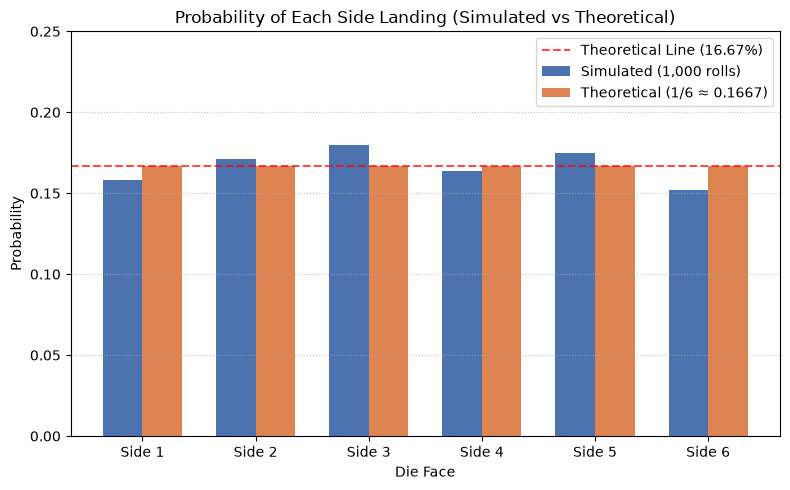

In [10]:
import random
import matplotlib.pyplot as plt
import numpy as np

# 1. Simulate 1,000 rolls of a 6-sided die
num_rolls = 1000
rolls = [random.randint(1, 6) for _ in range(num_rolls)]
faces = list(range(1, 7))

# 2. Calculate probabilities
empirical_probs = [rolls.count(f) / num_rolls for f in faces]
theoretical_prob = 1 / 6

# 3. Create side-by-side bar chart
x = np.arange(len(faces))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(
    x - width / 2,
    empirical_probs,
    width,
    label='Simulated (1,000 rolls)',
    color='#4C72B0',
)
plt.bar(
    x + width / 2,
    [theoretical_prob] * 6,
    width,
    label='Theoretical (1/6 ≈ 0.1667)',
    color='#DD8452',
)

# Reference dashed line for theoretical probability
plt.axhline(
    y=theoretical_prob,
    color='red',
    linestyle='--',
    alpha=0.7,
    label='Theoretical Line (16.67%)',
)

# Chart labels and styling
plt.xlabel('Die Face')
plt.ylabel('Probability')
plt.title('Probability of Each Side Landing (Simulated vs Theoretical)')
plt.xticks(x, [f'Side {f}' for f in faces])
plt.ylim(0, 0.25)
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

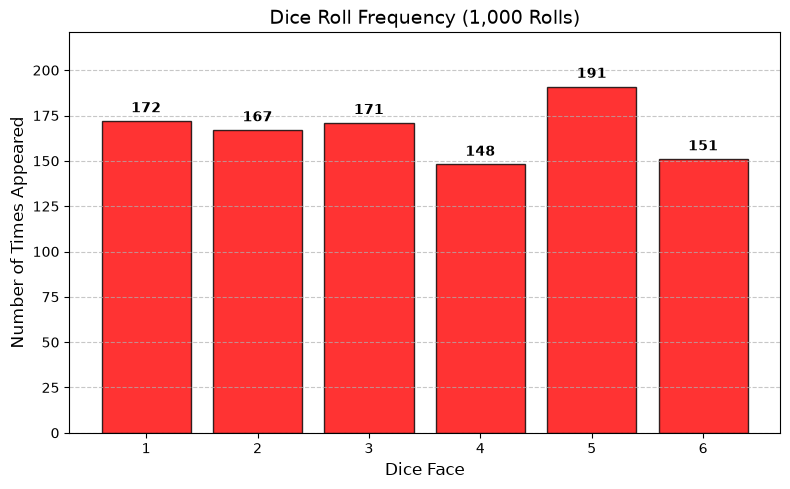

In [11]:
import random
import matplotlib.pyplot as plt

# 1. Simulate rolling a 6-sided die 1,000 times
num_rolls = 1000
rolls = [random.randint(1, 6) for _ in range(num_rolls)]
faces = list(range(1, 7))

# 2. Count how many times each face landed
counts = [rolls.count(f) for f in faces]

# 3. Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(faces, counts, color='red', edgecolor='black', alpha=0.8)

# Add titles and axis labels
plt.title('Dice Roll Frequency (1,000 Rolls)', fontsize=14)
plt.xlabel('Dice Face', fontsize=12)
plt.ylabel('Number of Times Appeared', fontsize=12)

# Ensure x-axis clearly labels values 1 through 6
plt.xticks(faces)
plt.ylim(0, max(counts) + 30)

# Display exact count labels on top of each bar
for face, count in zip(faces, counts):
    plt.text(
        face,
        count + 3,
        str(count),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
    )

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### My Conclusion
1. out of 1000 attempts, as I add my numbers that are odd, which are 1, 3 and 5. there is a 54.3% chance that upon rolling my dice, I will get an odd number.
   